In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from scipy.integrate import solve_ivp
from scipy.interpolate import make_interp_spline

def observed_order(N_values, err, n_fit=4):
    N_values = np.asarray(N_values, dtype=float)
    err = np.asarray(err, dtype=float)
    valid = np.isfinite(err) & (err > 0)
    idx = np.where(valid)[0][-min(n_fit, valid.sum()):]
    slope = np.polyfit(np.log(N_values[idx]), np.log(err[idx]), 1)[0]
    return -slope


# Exercise 1

m1,m2,k1,k2,c1,c2 = 1.0 1.0 4.0 2.0 0.1 0.1
Heun errors: [np.float64(657715.3131133254), np.float64(319.25541412216), np.float64(1.4483421607987055), np.float64(0.4278091564182419), np.float64(0.10865586830475622), np.float64(0.026583654532534872), np.float64(0.006512113940809435), np.float64(0.001607034358389151), np.float64(0.0003988552617413148)]
RK4 errors: [np.float64(1.265595646430181), np.float64(0.7204589080763861), np.float64(0.051233022797643704), np.float64(0.0026891159513209597), np.float64(0.00014913648111251687), np.float64(8.714802229594922e-06), np.float64(5.257423239115765e-07), np.float64(3.226976578296544e-08), np.float64(1.998532614441884e-09)]
Heun: observed order = 2.02 (theoretical 2)
RK4: observed order = 4.03 (theoretical 4)


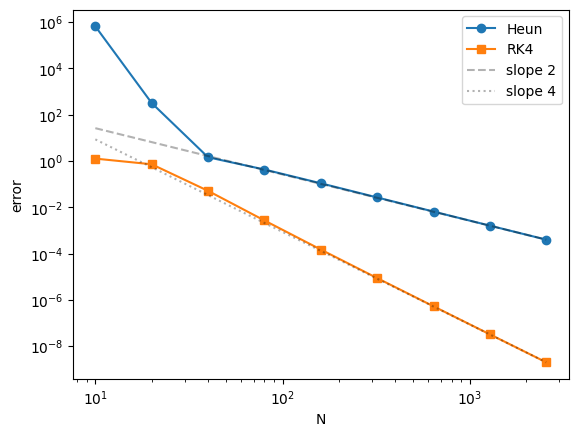

m1,m2,k1,k2,c1,c2 = 2.0 1.0 10.0 5.0 1.0 0.5
Heun errors: [np.float64(18252752.057978127), np.float64(3330.9249322705577), np.float64(0.37060185838895215), np.float64(0.18869228510340103), np.float64(0.049231811877180065), np.float64(0.012333254197904832), np.float64(0.003067979167393601), np.float64(0.0007634227356618135), np.float64(0.00019028551523833046)]
RK4 errors: [np.float64(354.15786050366603), np.float64(0.1052051199745378), np.float64(0.025750481370218625), np.float64(0.0016015451645654995), np.float64(9.496740019120061e-05), np.float64(5.724785825539231e-06), np.float64(3.504838133570559e-07), np.float64(2.16655878962432e-08), np.float64(1.3464392946167236e-09)]
Heun: observed order = 2.01 (theoretical 2)
RK4: observed order = 4.02 (theoretical 4)


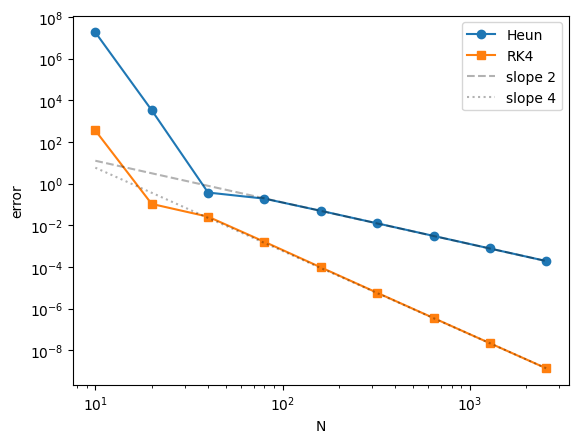

m1,m2,k1,k2,c1,c2 = 1.0 1.0 4.0 2.0 0.0 0.0
Heun errors: [np.float64(732816.9697312709), np.float64(475.41466590736655), np.float64(2.63755718468576), np.float64(0.7538978248739602), np.float64(0.1890301065126388), np.float64(0.04622315185542054), np.float64(0.01133535893994678), np.float64(0.002799670249155106), np.float64(0.0006952042281976707)]
RK4 errors: [np.float64(2.0865587625031994), np.float64(1.1423867222004058), np.float64(0.08686734763166287), np.float64(0.004723003233193959), np.float64(0.0002664701424203104), np.float64(1.570078304075332e-05), np.float64(9.509359410241248e-07), np.float64(5.847878218907201e-08), np.float64(3.6250472493507488e-09)]
Heun: observed order = 2.02 (theoretical 2)
RK4: observed order = 4.03 (theoretical 4)


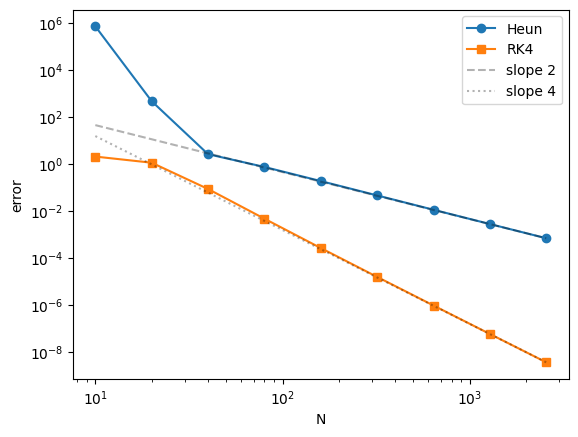

In [2]:
def A_matrix(m1, m2, k1, k2, c1, c2):
    return np.array([
        [0, 0, 1, 0],
        [0, 0, 0, 1],
        [-(k1 + k2) / m1, k2 / m1, -c1 / m1, 0],
        [k2 / m2, -k2 / m2, 0, -c2 / m2],
    ])

def heun_step(A, x, dt):
    k1 = A @ x
    k2 = A @ (x + dt * k1)
    return x + dt / 2 * (k1 + k2)

def rk4_step(A, x, dt):
    k1 = A @ x
    k2 = A @ (x + dt / 2 * k1)
    k3 = A @ (x + dt / 2 * k2)
    k4 = A @ (x + dt * k3)
    return x + dt / 6 * (k1 + 2 * k2 + 2 * k3 + k4)

x0 = np.array([1.0, 0.0, 0.0, 0.0])
T = 10.0
N_values = [10, 20, 40, 80, 160, 320, 640, 1280, 2560]

cases = [
    (1.0, 1.0, 4.0, 2.0, 0.1, 0.1),
    (2.0, 1.0, 10.0, 5.0, 1.0, 0.5),
    (1.0, 1.0, 4.0, 2.0, 0.0, 0.0),
]

for m1, m2, k1, k2, c1, c2 in cases:
    A = A_matrix(m1, m2, k1, k2, c1, c2)
    x_exact = expm(A * T) @ x0

    heun_errors = []
    rk4_errors = []
    for N in N_values:
        dt = T / N
        x_heun = x0.copy()
        x_rk4 = x0.copy()
        for n in range(N):
            x_heun = heun_step(A, x_heun, dt)
            x_rk4 = rk4_step(A, x_rk4, dt)
        heun_errors.append(np.linalg.norm(x_heun - x_exact))
        rk4_errors.append(np.linalg.norm(x_rk4 - x_exact))

    print("m1,m2,k1,k2,c1,c2 =", m1, m2, k1, k2, c1, c2)
    print("Heun errors:", heun_errors)
    print("RK4 errors:", rk4_errors)

    Nv = np.array(N_values, dtype=float)
    for name, err, order in [("Heun", heun_errors, 2), ("RK4", rk4_errors, 4)]:
        p = observed_order(N_values, err)
        print(f"{name}: observed order = {p:.2f} (theoretical {order})")

    plt.figure()
    plt.loglog(Nv, heun_errors, 'o-', label='Heun')
    plt.loglog(Nv, rk4_errors, 's-', label='RK4')
    plt.loglog(Nv, heun_errors[-1] * (Nv[-1] / Nv) ** 2, 'k--', alpha=0.3, label='slope 2')
    plt.loglog(Nv, rk4_errors[-1] * (Nv[-1] / Nv) ** 4, 'k:', alpha=0.3, label='slope 4')
    plt.xlabel('N')
    plt.ylabel('error')
    plt.legend()
    plt.show()


# Exercise 2

reference solution: [-6.5121137  -6.97404279 23.92412957]


C:\Users\ismag\AppData\Local\Temp\ipykernel_10404\3168443470.py:35: RuntimeWarning: overflow encountered in scalar multiply
  return np.array([-sigma * y1 + sigma * y2, r * y1 - y2 - y1 * y3, y1 * y2 - b * y3])
C:\Users\ismag\AppData\Local\Temp\ipykernel_10404\3168443470.py:35: RuntimeWarning: invalid value encountered in scalar subtract
  return np.array([-sigma * y1 + sigma * y2, r * y1 - y2 - y1 * y3, y1 * y2 - b * y3])
C:\Users\ismag\AppData\Local\Temp\ipykernel_10404\3168443470.py:9: RuntimeWarning: invalid value encountered in add
  return x + dt * sum(b[i] * k[i] for i in range(s))


Euler: errors = [np.float64(nan), np.float64(nan), np.float64(nan), np.float64(24.764403032768293), np.float64(7.483991977341982), np.float64(4.0062800234648535), np.float64(1.3487970802934597)]
Euler: observed order = 1.35 (theoretical 1)
Heun: errors = [np.float64(nan), np.float64(14.750114150291788), np.float64(2.18349777313143), np.float64(0.4301488266143437), np.float64(0.09226471810165787), np.float64(0.021480827164248713), np.float64(0.005201902615707733)]
Heun: observed order = 2.12 (theoretical 2)
RK3: errors = [np.float64(3.5392946547585624), np.float64(0.8633701154543504), np.float64(0.43071790031396806), np.float64(0.06521223728999248), np.float64(0.008483484254535297), np.float64(0.0010692747331055613), np.float64(0.0001338443541230118)]
RK3: observed order = 2.98 (theoretical 3)
RK4: errors = [np.float64(2.400608245621219), np.float64(0.616964056874808), np.float64(0.022804811049589504), np.float64(0.0007267470637707564), np.float64(2.5885690501353968e-05), np.float64(1.2

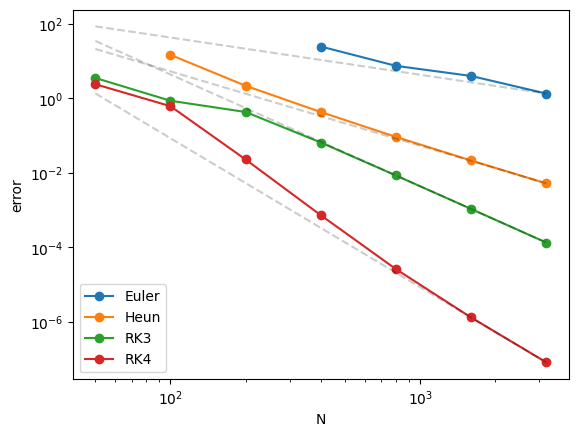

In [3]:
def rk_step(f, t, x, dt, A, b, c):
    s = len(b)
    k = np.zeros((s, len(x)))
    for i in range(s):
        xi = x.copy()
        for j in range(i):
            xi = xi + dt * A[i, j] * k[j]
        k[i] = f(t + c[i] * dt, xi)
    return x + dt * sum(b[i] * k[i] for i in range(s))

def rk_integrate(f, t0, x0, T, N, tableau):
    A, b, c = tableau
    dt = (T - t0) / N
    t = t0
    x = np.array(x0, dtype=float)
    for _ in range(N):
        x = rk_step(f, t, x, dt, A, b, c)
        t += dt
    return x

TABLEAUS = {
    "Euler": (np.array([[0.0]]), np.array([1.0]), np.array([0.0])),
    "Heun": (np.array([[0.0, 0.0], [1.0, 0.0]]), np.array([0.5, 0.5]), np.array([0.0, 1.0])),
    "RK3": (np.array([[0.0, 0.0, 0.0], [0.5, 0.0, 0.0], [-1.0, 2.0, 0.0]]),
            np.array([1/6, 2/3, 1/6]), np.array([0.0, 0.5, 1.0])),
    "RK4": (np.array([[0.0, 0.0, 0.0, 0.0], [0.5, 0.0, 0.0, 0.0],
                       [0.0, 0.5, 0.0, 0.0], [0.0, 0.0, 1.0, 0.0]]),
            np.array([1/6, 1/3, 1/3, 1/6]), np.array([0.0, 0.5, 0.5, 1.0])),
}

ORDERS = {"Euler": 1, "Heun": 2, "RK3": 3, "RK4": 4}

def lorenz(t, y, sigma=10.0, b=8.0/3.0, r=28.0):
    y1, y2, y3 = y
    return np.array([-sigma * y1 + sigma * y2, r * y1 - y2 - y1 * y3, y1 * y2 - b * y3])

y0 = [1.0, 1.0, 1.0]
T = 5.0
ref = solve_ivp(lorenz, [0, T], y0, method="DOP853", rtol=1e-12, atol=1e-12)
y_ref = ref.y[:, -1]
print("reference solution:", y_ref)

N_values = [50, 100, 200, 400, 800, 1600, 3200]

errors = {name: [] for name in TABLEAUS}
for N in N_values:
    for name, tab in TABLEAUS.items():
        y_num = rk_integrate(lorenz, 0.0, y0, T, N, tab)
        errors[name].append(np.linalg.norm(y_num - y_ref))

Nv = np.array(N_values, dtype=float)
for name in TABLEAUS:
    err = errors[name]
    p = observed_order(N_values, err)
    print(f"{name}: errors = {err}")
    print(f"{name}: observed order = {p:.2f} (theoretical {ORDERS[name]})")

plt.figure()
for name in TABLEAUS:
    plt.loglog(Nv, errors[name], 'o-', label=name)
    plt.loglog(Nv, errors[name][-1] * (Nv[-1] / Nv) ** ORDERS[name], 'k--', alpha=0.2)
plt.xlabel('N')
plt.ylabel('error')
plt.legend()
plt.show()


# Exercise 3

M = 20 dx = 0.5
Euler: errors = [np.float64(0.02880126524751187), np.float64(0.014239584139111278), np.float64(0.0070774296962010244), np.float64(0.003527881868701287), np.float64(0.0017612036588958624), np.float64(0.0008799139592048321)]
Euler: observed order = 1.00 (theoretical 1)
Heun: errors = [np.float64(0.00042470593852627394), np.float64(0.00010604062429133211), np.float64(2.649317004114961e-05), np.float64(6.621155743779863e-06), np.float64(1.6550148838528473e-06), np.float64(4.13713151435733e-07)]
Heun: observed order = 2.00 (theoretical 2)
RK3: errors = [np.float64(5.249648820147856e-06), np.float64(6.609657164982688e-07), np.float64(8.29379814109611e-08), np.float64(1.0392701360359584e-08), np.float64(1.305912083972005e-09), np.float64(1.691314886224403e-10)]
RK3: observed order = 2.98 (theoretical 3)
RK4: errors = [np.float64(7.684962629588216e-08), np.float64(4.828510747281379e-09), np.float64(3.0471446100069983e-10), np.float64(2.3925164296633745e-11), np.float64(1.192084

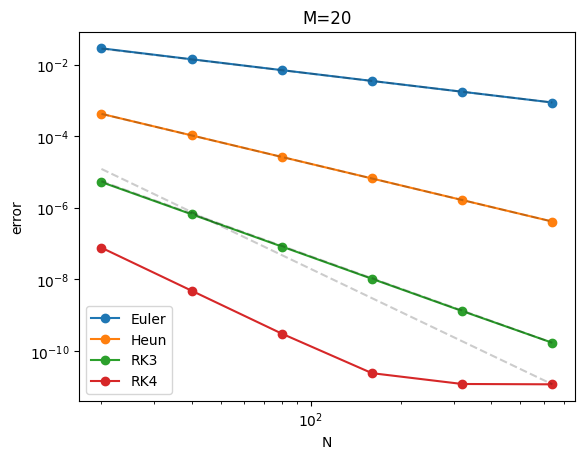

M = 50 dx = 0.2
Euler: errors = [np.float64(0.10159337200238307), np.float64(0.0485954117240684), np.float64(0.02373335396466538), np.float64(0.011724308780115388), np.float64(0.005826439984946979), np.float64(0.002904278736360228)]
Euler: observed order = 1.01 (theoretical 1)
Heun: errors = [np.float64(0.004306095172397138), np.float64(0.0010739504155556309), np.float64(0.00026833771294536556), np.float64(6.707349409641913e-05), np.float64(1.6767401352162046e-05), np.float64(4.191755361763726e-06)]
Heun: observed order = 2.00 (theoretical 2)
RK3: errors = [np.float64(0.00017377515780856394), np.float64(2.1839819566053764e-05), np.float64(2.7369136364593772e-06), np.float64(3.4253758103112704e-07), np.float64(4.283943222176821e-08), np.float64(5.352131585330579e-09)]
RK3: observed order = 3.00 (theoretical 3)
RK4: errors = [np.float64(6.251721834239737e-06), np.float64(3.888957920857286e-07), np.float64(2.423452610261974e-08), np.float64(1.503282693899496e-09), np.float64(8.49159433566

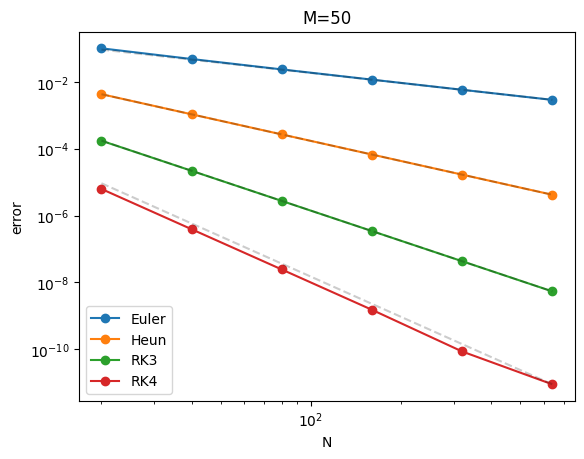

In [4]:
def burgers_rhs(t, y, nu, dx):
    y_ext = np.concatenate(([0.0], y, [0.0]))
    yc = y_ext[1:-1]
    yp = y_ext[2:]
    ym = y_ext[:-2]
    return -yc * (yp - ym) / (2 * dx) + nu * (yp - 2 * yc + ym) / dx ** 2

nu = 0.01
L = 10.0
T = 1.0
M_values = [20, 50]
N_values = [20, 40, 80, 160, 320, 640]
Nv = np.array(N_values, dtype=float)

for M in M_values:
    dx = L / M
    x = np.arange(1, M) * dx
    y0 = np.exp(-((x - 0.5 * L) / (0.1 * L)) ** 2)
    f = lambda t, y: burgers_rhs(t, y, nu, dx)

    y_ref = solve_ivp(f, [0, T], y0, method="DOP853", rtol=1e-11, atol=1e-11, t_eval=[T]).y[:, -1]

    errors = {name: [] for name in TABLEAUS}
    for N in N_values:
        for name, tab in TABLEAUS.items():
            y_num = rk_integrate(f, 0.0, y0, T, N, tab)
            errors[name].append(np.linalg.norm(y_num - y_ref))

    print("M =", M, "dx =", dx)
    for name in TABLEAUS:
        err = errors[name]
        p = observed_order(N_values, err)
        print(f"{name}: errors = {err}")
        print(f"{name}: observed order = {p:.2f} (theoretical {ORDERS[name]})")

    plt.figure()
    for name in TABLEAUS:
        plt.loglog(Nv, errors[name], 'o-', label=name)
        plt.loglog(Nv, errors[name][-1] * (Nv[-1] / Nv) ** ORDERS[name], 'k--', alpha=0.2)
    plt.xlabel('N')
    plt.ylabel('error')
    plt.title(f"M={M}")
    plt.legend()
    plt.show()


# Exercise 4

adaptive steps: 1314
adaptive max error: 0.009244085488960024
fixed-step max error (same number of steps): 4.036366909504839e-06


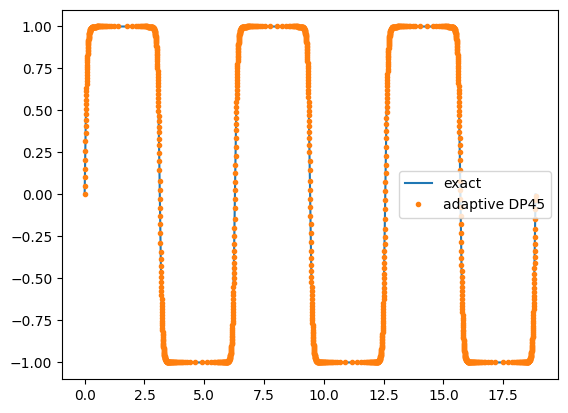

In [5]:
alpha = 20.0

def f(t, y):
    return alpha / 2 * np.cos(t) * (1 - y ** 2)

def exact(t):
    return np.tanh(alpha * np.sin(t) / 2)

c = np.array([0, 1/5, 3/10, 4/5, 8/9, 1, 1])
A = np.zeros((7, 7))
A[1, 0] = 1/5
A[2, 0], A[2, 1] = 3/40, 9/40
A[3, 0], A[3, 1], A[3, 2] = 44/45, -56/15, 32/9
A[4, 0], A[4, 1], A[4, 2], A[4, 3] = 19372/6561, -25360/2187, 64448/6561, -212/729
A[5, 0], A[5, 1], A[5, 2], A[5, 3], A[5, 4] = 9017/3168, -355/33, 46732/5247, 49/176, -5103/18656
A[6, 0], A[6, 1], A[6, 2], A[6, 3], A[6, 4], A[6, 5] = 35/384, 0, 500/1113, 125/192, -2187/6784, 11/84
b5 = np.array([35/384, 0, 500/1113, 125/192, -2187/6784, 11/84, 0])
b4 = np.array([5179/57600, 0, 7571/16695, 393/640, -92097/339200, 187/2100, 1/40])

def dp45_step(f, t, y, dt):
    k = np.zeros(7)
    for i in range(7):
        yi = y
        for j in range(i):
            yi = yi + dt * A[i, j] * k[j]
        k[i] = f(t + c[i] * dt, yi)
    y5 = y + dt * np.dot(b5, k)
    y4 = y + dt * np.dot(b4, k)
    return y5, y4

def dp45_adaptive(f, t0, y0, T, atol=1e-8, rtol=1e-8):
    t, y = t0, y0
    dt = (T - t0) / 100
    ts, ys = [t], [y]
    while t < T:
        if t + dt > T:
            dt = T - t
        y5, y4 = dp45_step(f, t, y, dt)
        err = abs(y5 - y4) / (atol + rtol * abs(y5))
        if err <= 1.0:
            t, y = t + dt, y5
            ts.append(t)
            ys.append(y)
            dt *= min(5.0, max(0.2, 0.9 * err ** (-0.2))) if err > 0 else dt * 5.0
        else:
            dt *= max(0.2, 0.9 * err ** (-0.2))
    return np.array(ts), np.array(ys)

def dp45_fixed(f, t0, y0, T, N):
    dt = (T - t0) / N
    ts = np.linspace(t0, T, N + 1)
    ys = np.empty(N + 1)
    ys[0] = y0
    t, y = t0, y0
    for i in range(N):
        y, _ = dp45_step(f, t, y, dt)
        t += dt
        ys[i + 1] = y
    return ts, ys

T = 6 * np.pi
ts, ys = dp45_adaptive(f, 0.0, 0.0, T, atol=1e-10, rtol=1e-10)
print("adaptive steps:", len(ts) - 1)

spline = make_interp_spline(ts, ys, k=5)
t_fine = np.linspace(0, T, 2000)
err_adaptive = np.max(np.abs(spline(t_fine) - exact(t_fine)))
print("adaptive max error:", err_adaptive)

ts_f, ys_f = dp45_fixed(f, 0.0, 0.0, T, len(ts) - 1)
err_fixed = np.max(np.abs(ys_f - exact(ts_f)))
print("fixed-step max error (same number of steps):", err_fixed)

plt.figure()
plt.plot(t_fine, exact(t_fine), label='exact')
plt.plot(ts, ys, '.', label='adaptive DP45')
plt.legend()
plt.show()
